## Importando Bibliotecas e Carregando os Dados

In [81]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 
from pathlib import Path
from scipy.stats import iqr

In [ ]:
caminho_atual = Path(".").resolve()
arquivos = caminho_atual.parent / "data" / "raw" / "train.csv"

df = pd.read_csv(arquivos)

## Análise das variáveis

In [83]:
display(df.head())

print(f"Amostras/Linhas: {df.shape[0]}")
print(f"Features: {df.shape[1]}")

,Survived,Pclass,Name,Sex,Age,siblings,Parch,Ticket,Fare,Cabin,Embarked
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7925.0000,NaN,S
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q


Amostras/Linhas: 712
Features: 11


## Identificação de valores ausentes, outliers e possíveis inconsistências

In [84]:
summary_list = []

for col in df.columns:
    # Calcula nulos por Pclass apenas se a coluna tiver nulos e não for a própria Pclass
    if col != "Pclass" and df[col].isnull().sum() > 0:
        nulos_por_pclass = df[col].isnull().groupby(df["Pclass"]).sum().to_dict()
    else:
        nulos_por_pclass = None

    summary_list.append({
        'Feature': col,
        'Tipo de Dado': df[col].dtype,
        'Valores Totais': df[col].count(),
        'Valores Nulos': df[col].isnull().sum(),
        'Proporção de Valores Nulos': f"{df[col].isnull().mean():.2%}",
        'Nulos por Pclass': nulos_por_pclass,
        'Valores Únicos': df[col].nunique(),
        'Valores Duplicados': df[col].duplicated().sum(),
        'Exemplos': df[col].value_counts(dropna=False).head(3).index.tolist()
    })

summary_df = pd.DataFrame(summary_list)
display(summary_df)

,Feature,Tipo de Dado,Valores Totais,Valores Nulos,Proporção de Valores Nulos,Nulos por Pclass,Valores Únicos,Valores Duplicados,Exemplos
0,Survived,int64,712,0,0.00%,None,2,710,"[0, 1]"
1,Pclass,int64,712,0,0.00%,None,3,709,"[3, 1, 2]"
2,Name,str,712,0,0.00%,None,712,0,"[Braund, Mr. Owen Harris, Cumings, Mrs. John B..."
3,Sex,str,712,0,0.00%,None,2,710,"[male, female]"
4,Age,float64,575,137,19.24%,"{1: 26, 2: 9, 3: 102}",85,626,"[nan, 22.0, 18.0]"
5,siblings,int64,712,0,0.00%,None,7,705,"[0, 1, 2]"
6,Parch,int64,712,0,0.00%,None,7,705,"[0, 1, 2]"
7,Ticket,str,712,0,0.00%,None,571,141,"[347082, 1601, 3101295]"
8,Fare,float64,712,0,0.00%,None,226,486,"[13.0, 8.05, 7.8958]"
9,Cabin,str,160,552,77.53%,"{1: 35, 2: 135, 3: 382}",127,584,"[nan, G6, F33]"


- Devemos passar "Sex" para int64, permitindo calcular correlaçao com Survided

- Embarked tbm, porém aplicando one-hot-enconding. Por se tratar de uma varável nominal, se mudarmos S = 0, C= 1 e Q = 2, Q será matematicamento representado como 2 vezes maior que Q. 

- Nota-se que foram perdidos muitos dados da Pclass = 3: 102 registros de Idade e 382 registros de Cabin(Tinham cabines porém perderam os registros ou nem tinham cabine dês do início) 

In [85]:
# Cabines faltando de cada classe (quantidade e porcentagem)
cabines_faltando = df.groupby("Pclass")["Cabin"].agg(
    total="size",
    presentes="count",
    faltando=lambda x: x.isna().sum(),
    pct_faltando=lambda x: f"{(x.isna().mean() * 100):.1f}%"
)
display(cabines_faltando)
idade_faltando = df.groupby("Pclass")["Age"].agg(
    total="size",
    presentes="count",
    faltando=lambda x: x.isna().sum(),
    pct_faltando=lambda x: f"{(x.isna().mean() * 100):.1f}%"
)
display(idade_faltando)

,total,presentes,faltando,pct_faltando
Pclass,,,,
1,171,136,35,20.5%
2,150,15,135,90.0%
3,391,9,382,97.7%


,total,presentes,faltando,pct_faltando
Pclass,,,,
1,171,145,26,15.2%
2,150,141,9,6.0%
3,391,289,102,26.1%


Diferença entre Fare errado e Fare corrigido (.head()):


,Name,Pclass,Fare_errado,Fare
0,"Braund, Mr. Owen Harris",3,7.2500,7.2500
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,71.2833,71.2833
2,"Heikkinen, Miss. Laina",3,7925.0000,7.9250
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,53.1000,53.1000
4,"Moran, Mr. James",3,8.4583,8.4583
5,"McCarthy, Mr. Timothy J",1,51.8625,51.8625
6,"Palsson, Master. Gosta Leonard",3,21075.0000,21.0750
7,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",3,11.1333,11.1333
8,"Sandstrom, Miss. Marguerite Rut",3,16.7000,16.7000
9,"Saundercock, Mr. William Henry",3,8.0500,8.0500


Resumo de Outliers pelo Método IQR (Fare errado vs corrigido):


,Feature,Q1 (25%),Mediana (50%),Q3 (75%),IQR,Limite Inferior,Limite Superior,Qtd Outliers,% Outliers
0,Age,21.00,28.50,39.00,18.00,-6.00,66.00,6,0.84%
1,Fare_errado,8.05,19.38,56.93,48.88,-65.27,130.25,114,16.01%
2,Fare,7.90,14.45,31.00,23.10,-26.76,65.66,91,12.78%
3,siblings,0.00,0.00,1.00,1.00,-1.50,2.50,33,4.63%
4,Parch,0.00,0.00,0.00,0.00,0.00,0.00,170,23.88%


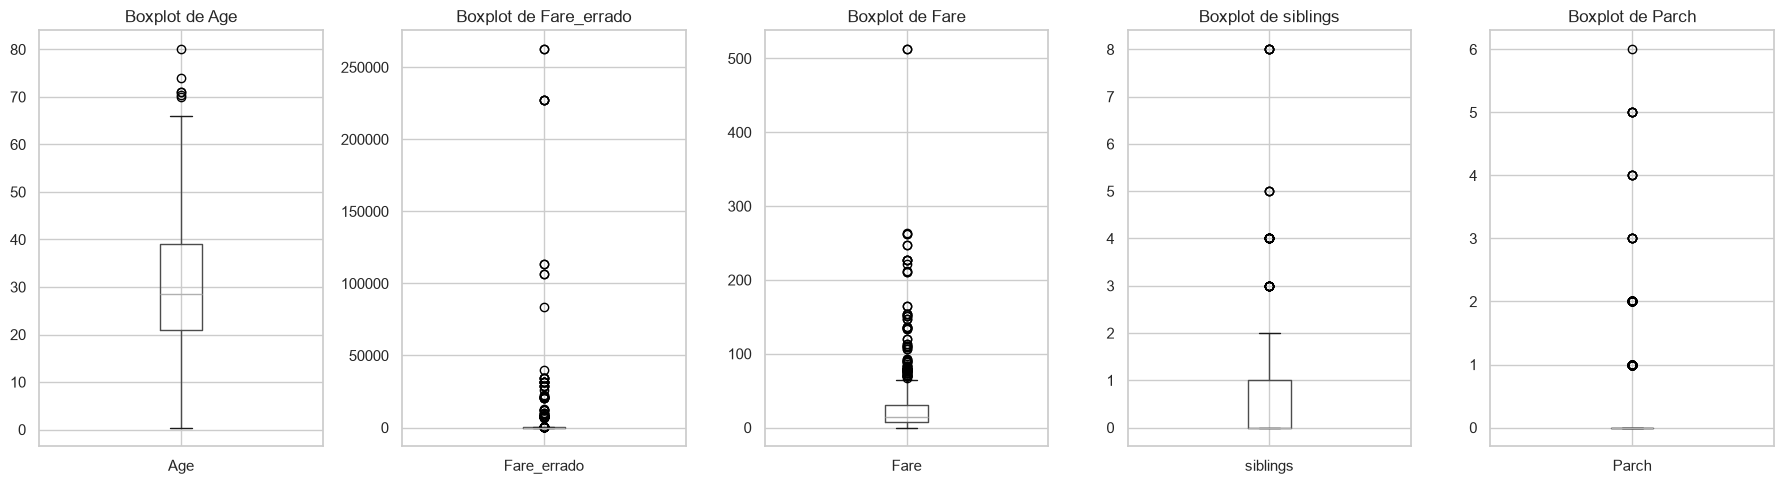

In [86]:
# Valores de Fare acima de 513 perderam o ponto decimal na exportação (foram multiplicados por 1000)
df["Fare_errado"] = df["Fare"]
df["Fare"] = df["Fare"].apply(lambda x: x / 1000 if x > 513 else x)

print("Diferença entre Fare errado e Fare corrigido (.head()):")
display(df[["Name", "Pclass", "Fare_errado", "Fare"]].head(10))

# 1. Selecionamos as variáveis numéricas para comparar o IQR antes e depois do ajuste
colunas_numericas = ["Age", "Fare_errado", "Fare", "siblings", "Parch"]

# 2. Cálculo do IQR e identificação dos outliers
resumo_outliers = []
for col in colunas_numericas:
    dados_validos = df[col].dropna()
    
    q1 = dados_validos.quantile(0.25)
    q3 = dados_validos.quantile(0.75)
    valor_iqr = q3 - q1
    
    limite_inferior = q1 - 1.5 * valor_iqr
    limite_superior = q3 + 1.5 * valor_iqr
    
    mask_outlier = (df[col] < limite_inferior) | (df[col] > limite_superior)
    qtd_outliers = mask_outlier.sum()
    pct_outliers = (qtd_outliers / len(df)) * 100
    
    resumo_outliers.append({
        "Feature": col,
        "Q1 (25%)": round(q1, 2),
        "Mediana (50%)": round(dados_validos.median(), 2),
        "Q3 (75%)": round(q3, 2),
        "IQR": round(valor_iqr, 2),
        "Limite Inferior": round(limite_inferior, 2),
        "Limite Superior": round(limite_superior, 2),
        "Qtd Outliers": qtd_outliers,
        "% Outliers": f"{pct_outliers:.2f}%"
    })

df_resumo_outliers = pd.DataFrame(resumo_outliers)
print("Resumo de Outliers pelo Método IQR (Fare errado vs corrigido):")
display(df_resumo_outliers)

# 3. Visualização Gráfica (Boxplots com Fare errado e corrigido lado a lado)
fig, axes = plt.subplots(nrows=1, ncols=len(colunas_numericas), figsize=(18, 5))
for i, col in enumerate(colunas_numericas):
    df.boxplot(column=col, ax=axes[i], grid=True)
    axes[i].set_title(f"Boxplot de {col}")
plt.tight_layout()
plt.show()

# Remove a coluna auxiliar para seguir as próximas análises com o Fare corrigido
df.drop(columns=["Fare_errado"], inplace=True)

- Age: Os outliers são os idosos com mais de 66 anos
- Fare: Tinha valores multiplicados por 1000 por erro de casa decimal (ex: 7925 no lugar de 7.925). Mesmo corrigindo, ainda existem outliers reais porque muitos viajavam sozinhos e outros em família ou na 1ª classe, o que muda bastante o valor do bilhete.

Primeiras linhas com as novas features:


,Name,siblings,Parch,family_size,is_alone,Fare,fare_per_person,Survived
0,"Braund, Mr. Owen Harris",1,0,2,0,7.2500,3.62500,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,0,2,0,71.2833,35.64165,1
2,"Heikkinen, Miss. Laina",0,0,1,1,7.9250,7.92500,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,0,2,0,53.1000,26.55000,1
4,"Moran, Mr. James",0,0,1,1,8.4583,8.45830,0



Comparativo Estatístico: Fare Total vs Fare por Pessoa:


,Fare,fare_per_person
count,712.00,712.00
mean,31.82,20.40
std,48.06,37.72
min,0.00,0.00
25%,7.90,7.25
50%,14.45,8.45
75%,31.00,20.48
max,512.33,512.33


,Feature,IQR,Limite Superior (Outlier),Qtd Outliers,% Outliers
0,Fare,23.10,65.66,91,12.78%
1,fare_per_person,13.23,40.33,76,10.67%


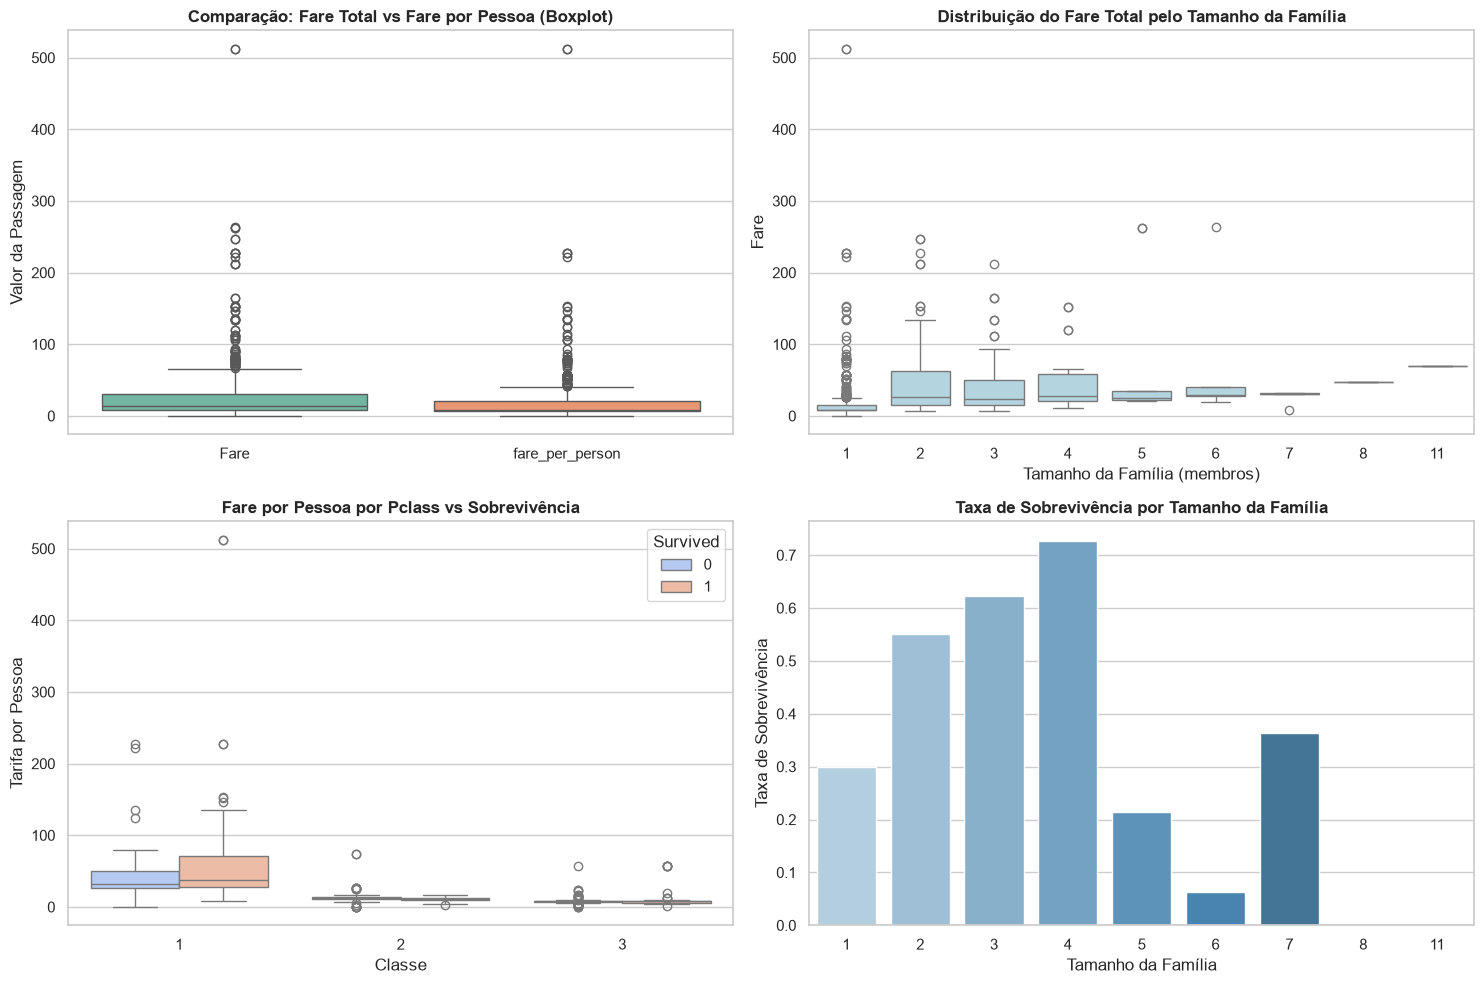


Correlações com Sobrevivência (Survived) após corrigir Fare:


Survived           1.000000
Fare               0.275499
fare_per_person    0.221981
family_size        0.026967
is_alone          -0.215570
Name: Survived, dtype: float64

In [87]:
df_transformed = df.copy()
sns.set_theme(style="whitegrid")

# 1. Criação das features de Família
# family_size: total de membros (irmãos + cônjuges + pais + filhos + o próprio passageiro)
df_transformed["family_size"] = df["siblings"] + df["Parch"] + 1

# Classificação em categorias de tamanho de família
df_transformed["is_alone"] = (df_transformed["family_size"] == 1).astype(int)

# Tarifa individual estimada (evita a distorção do bilhete conjunto)
df_transformed["fare_per_person"] = df_transformed["Fare"] / df_transformed["family_size"]

print("Primeiras linhas com as novas features:")
display(df_transformed[["Name", "siblings", "Parch", "family_size", "is_alone", "Fare", "fare_per_person", "Survived"]].head())

# 2. Estatísticas Descritivas: Fare Total vs Fare por Pessoa
print("\nComparativo Estatístico: Fare Total vs Fare por Pessoa:")
display(df_transformed[["Fare", "fare_per_person"]].describe().round(2))

# 3. Análise de Outliers: Fare Total vs Fare por Pessoa (IQR)
resumo_fare_outliers = []
for col in ["Fare", "fare_per_person"]:
    dados = df_transformed[col].dropna()
    valor_iqr = iqr(dados)
    q1 = dados.quantile(0.25)
    q3 = dados.quantile(0.75)
    sup = q3 + 1.5 * valor_iqr
    
    qtd_outliers = (dados > sup).sum()
    pct_outliers = (qtd_outliers / len(dados)) * 100
    
    resumo_fare_outliers.append({
        "Feature": col,
        "IQR": round(valor_iqr, 2),
        "Limite Superior (Outlier)": round(sup, 2),
        "Qtd Outliers": qtd_outliers,
        "% Outliers": f"{pct_outliers:.2f}%"
    })

display(pd.DataFrame(resumo_fare_outliers))

# 4. Visualizações Gráficas
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))

sns.boxplot(data=df_transformed[["Fare", "fare_per_person"]], ax=axes[0, 0], palette="Set2")
axes[0, 0].set_title("Comparação: Fare Total vs Fare por Pessoa (Boxplot)", fontweight="bold")
axes[0, 0].set_ylabel("Valor da Passagem")

sns.boxplot(data=df_transformed, x="family_size", y="Fare", ax=axes[0, 1], color="lightblue")
axes[0, 1].set_title("Distribuição do Fare Total pelo Tamanho da Família", fontweight="bold")
axes[0, 1].set_xlabel("Tamanho da Família (membros)")

sns.boxplot(data=df_transformed, x="Pclass", y="fare_per_person", hue="Survived", ax=axes[1, 0], palette="coolwarm")
axes[1, 0].set_title("Fare por Pessoa por Pclass vs Sobrevivência", fontweight="bold")
axes[1, 0].set_xlabel("Classe")
axes[1, 0].set_ylabel("Tarifa por Pessoa")

sns.barplot(data=df_transformed, x="family_size", y="Survived", hue="family_size", ax=axes[1, 1], palette="Blues_d", legend=False, errorbar=None)
axes[1, 1].set_title("Taxa de Sobrevivência por Tamanho da Família", fontweight="bold")
axes[1, 1].set_xlabel("Tamanho da Família")
axes[1, 1].set_ylabel("Taxa de Sobrevivência")

plt.tight_layout()
plt.show()

# 5. Correlação com Sobrevivência após ajuste do Fare
print("\nCorrelações com Sobrevivência (Survived) após corrigir Fare:")
display(df_transformed[["Fare", "fare_per_person", "family_size", "is_alone", "Survived"]].corr()["Survived"].sort_values(ascending=False))

## Analisando a Distribuição dos dados

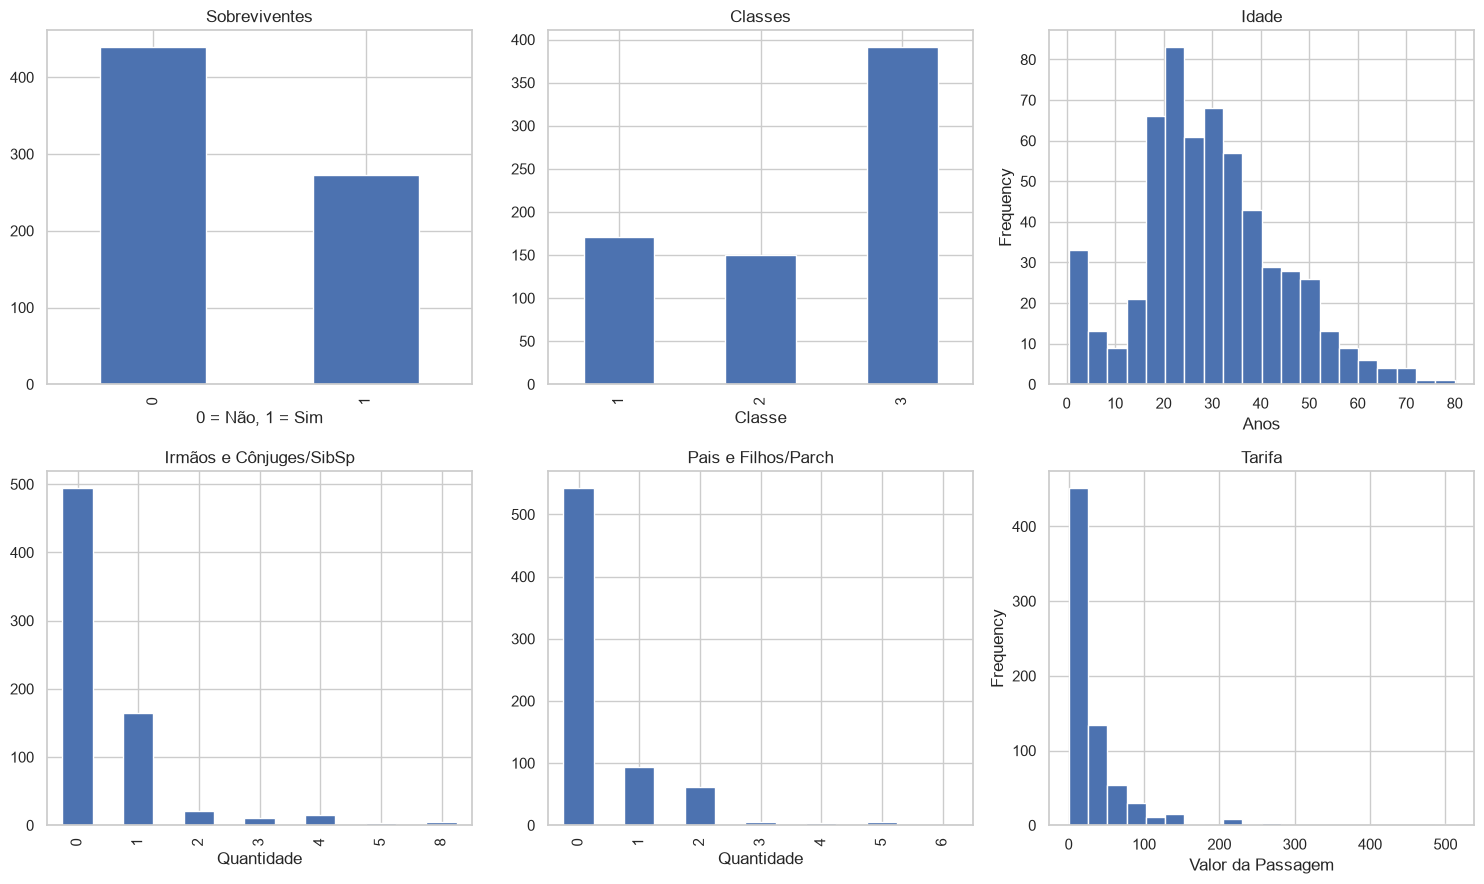

In [88]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 9))
# 1. Sobreviventes
df["Survived"].value_counts().plot(kind="bar", ax=axes[0, 0], title="Sobreviventes")
axes[0, 0].set_xlabel("0 = Não, 1 = Sim")
# 2. Classes
df["Pclass"].value_counts().sort_index().plot(kind="bar", ax=axes[0, 1], title="Classes")
axes[0, 1].set_xlabel("Classe")
# 3. Idade
df["Age"].plot(kind="hist", bins=20, ax=axes[0, 2], title="Idade")
axes[0, 2].set_xlabel("Anos")
# 4. Irmãos / Cônjuges (siblings em minúsculo)
df["siblings"].value_counts().sort_index().plot(kind="bar", ax=axes[1, 0], title="Irmãos e Cônjuges/SibSp")
axes[1, 0].set_xlabel("Quantidade")
# 5. Pais / Filhos
df["Parch"].value_counts().sort_index().plot(kind="bar", ax=axes[1, 1], title="Pais e Filhos/Parch")
axes[1, 1].set_xlabel("Quantidade")
# 6. Tarifa
df["Fare"].plot(kind="hist", bins=20, ax=axes[1, 2], title="Tarifa")
axes[1, 2].set_xlabel("Valor da Passagem")
plt.tight_layout()
plt.show()

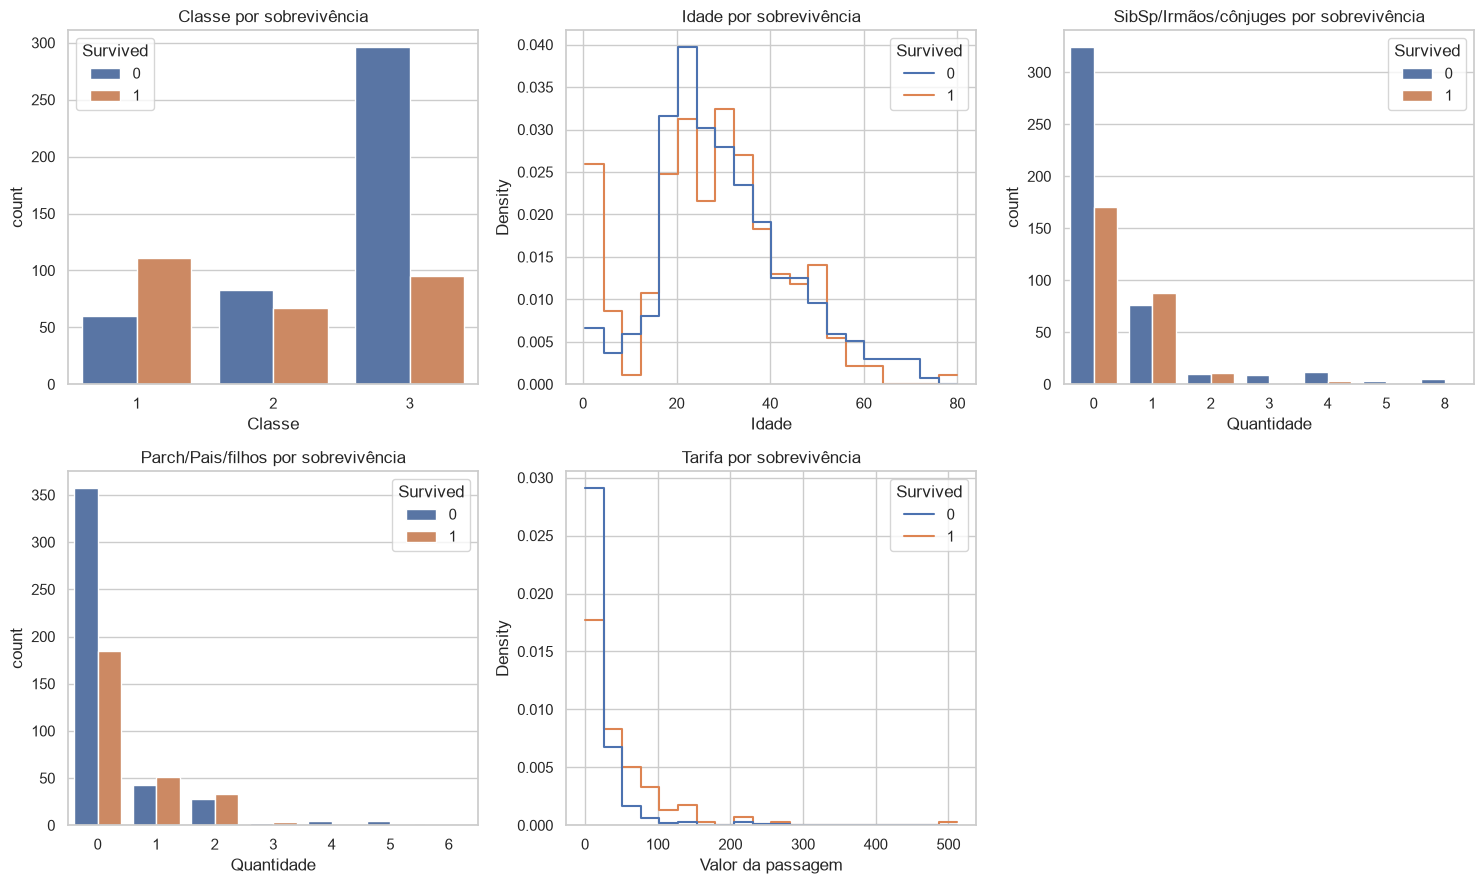

In [89]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 9))
axes = axes.flatten()

# Variáveis categóricas
sns.countplot(data=df, x="Pclass", hue="Survived", ax=axes[0])
axes[0].set_title("Classe por sobrevivência")
axes[0].set_xlabel("Classe")

sns.histplot(
    data=df, x="Age", hue="Survived",
    bins=20, stat="density", common_norm=False,
    element="step", fill=False, ax=axes[1]
)
axes[1].set_title("Idade por sobrevivência")
axes[1].set_xlabel("Idade")

sns.countplot(data=df, x="siblings", hue="Survived", ax=axes[2])
axes[2].set_title("SibSp/Irmãos/cônjuges por sobrevivência")
axes[2].set_xlabel("Quantidade")

sns.countplot(data=df, x="Parch", hue="Survived", ax=axes[3])
axes[3].set_title("Parch/Pais/filhos por sobrevivência")
axes[3].set_xlabel("Quantidade")

sns.histplot(
    data=df, x="Fare", hue="Survived",
    bins=20, stat="density", common_norm=False,
    element="step", fill=False, ax=axes[4]
)
axes[4].set_title("Tarifa por sobrevivência")
axes[4].set_xlabel("Valor da passagem")

# Remove o sexto painel, que não será usado
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

## investigação das relações entre as características dos passageiros e a sobrevivência.

Estatistica Descritiva de cada feature


,Survived,Pclass,Age,siblings,Parch,Fare
count,712.000000,712.000000,575.000000,712.000000,712.000000,712.000000
mean,0.383427,2.308989,29.807687,0.492978,0.390449,31.819826
std,0.486563,0.833563,14.485211,1.060720,0.838134,48.059104
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,21.000000,0.000000,0.000000,7.895800
50%,0.000000,3.000000,28.500000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,39.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Correlação entre as features
Features mais relevantes para a Sobrevivência:


Survived           1.000000
Sex                0.549171
Fare               0.275499
fare_per_person    0.221981
Embarked_C         0.180029
Embarked_S        -0.186567
is_alone          -0.215570
Pclass            -0.348007
Name: Survived, dtype: float64

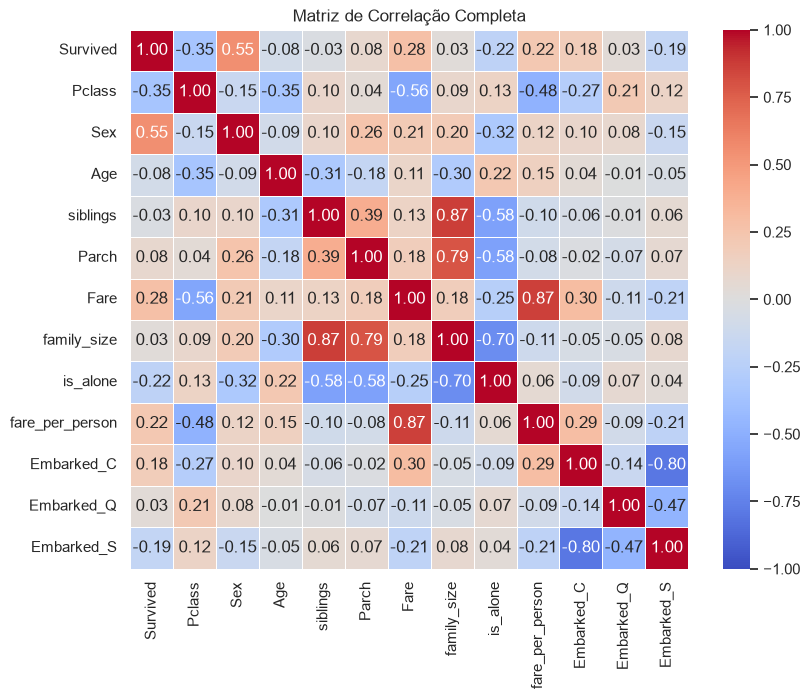

In [90]:
print("Estatistica Descritiva de cada feature")
display(df.describe())

print("Correlação entre as features")
map_sex = {
    "male": 0,
    "female": 1
}

# Tratamento de dados str para int64, permitindo que correlacionemos com Survived
df_transformed["Sex"] = df["Sex"].map(map_sex)

# One-Hot Encoding para Embarked (gera colunas: Embarked_C, Embarked_Q, Embarked_S com 0 ou 1)
df_transformed = pd.get_dummies(df_transformed, columns=["Embarked"], dtype=int)

# Calculando a matriz de correlação
matriz_correlacao = df_transformed.select_dtypes(include=["float64", "int64"]).corr()

corr_alvo = matriz_correlacao["Survived"].sort_values(ascending=False)
# Mostra apenas variáveis com correlação relevante (ex: maior que 0.1 ou menor que -0.1)
relevantes = corr_alvo[abs(corr_alvo) > 0.1]
print("Features mais relevantes para a Sobrevivência:")
display(relevantes)

plt.figure(figsize=(9, 7))
# Plot do mapa de calor com valores em cada célula
sns.heatmap(
    matriz_correlacao,
    annot=True,          # Mostra os valores numéricos
    fmt=".2f",           # 2 casas decimais
    cmap="coolwarm",     # Azul (negativo) -> Vermelho (positivo)
    vmin=-1, vmax=1,     # Escala de -1 a 1
    linewidths=0.5
)
plt.title("Matriz de Correlação Completa")
plt.show()

*Interpretaçao da Correlaçao de Pearson*

- 0.00 a 0.19: Correlação bem fraca ou irrelevante.
- 0.20 a 0.39: Correlação fraca/moderada.
- 0.40 a 0.69: Correlação moderada/forte (aqui o sinal de alerta acende).
- 0.70 a 1.00: Correlação muito forte (indica forte dependência linear).


Deck_D          0.169875
Deck_B          0.162058
Deck_E          0.159005
Deck_C          0.152263
Deck_F          0.088586
Deck_G          0.018021
Deck_A          0.013149
Deck_T         -0.029574
Deck_Unknown   -0.350535
Name: Survived, dtype: float64

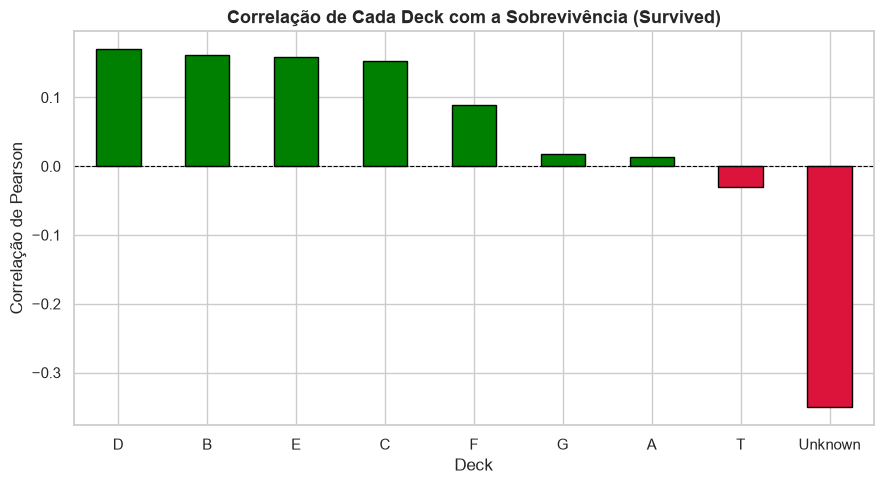

In [91]:
# 1. Extrai a primeira letra da cabine (se for nula, preenche com 'Unknown')
df_transformed["Deck"] = df["Cabin"].str[0].fillna("Unknown")

# 2. Transforma em colunas 0 e 1 (One-Hot Encoding) garantindo tipo numérico
df_transformed = pd.get_dummies(df_transformed, columns=["Deck"], dtype=int)

# 3. Calcula a correlação de todos os Decks com a sobrevivência
corr_decks = df_transformed.select_dtypes(include=["number"]).corr()["Survived"]
decks_corr = corr_decks.filter(like="Deck_").sort_values(ascending=False)

# Exibe os valores em texto/tabela
display(decks_corr)

# Remove "Deck_" dos nomes
decks_corr_plot = decks_corr.rename(
    index=lambda nome: nome.removeprefix("Deck_")
)

# 4. Gera o Gráfico de Barras da Correlação com Seaborn / Matplotlib
plt.figure(figsize=(9, 5))

cores = ["green" if valor > 0 else "crimson" for valor in decks_corr.values]
decks_corr_plot.plot(kind="bar", color=cores, edgecolor="black")
plt.title("Correlação de Cada Deck com a Sobrevivência (Survived)", fontsize=13, fontweight="bold")
plt.xlabel("Deck")
plt.ylabel("Correlação de Pearson")
plt.axhline(0, color="black", linestyle="--", linewidth=0.8) # Linha zero de referência
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

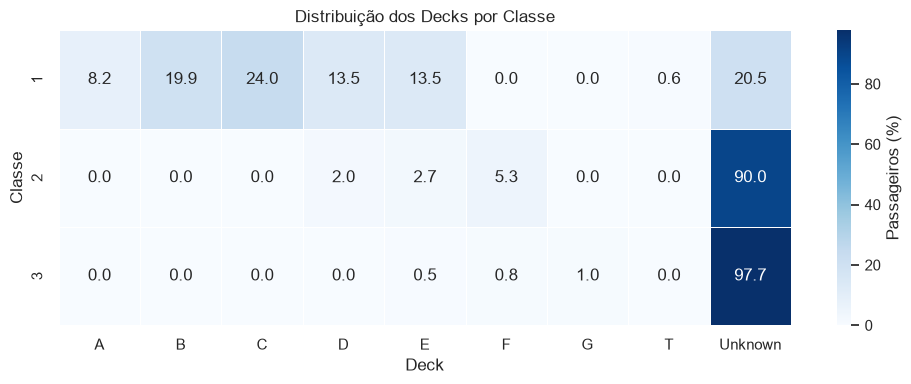

In [92]:
# Seleciona as colunas one-hot dos decks
deck_cols = [col for col in df_transformed.columns if col.startswith("Deck_")]

# Conta os passageiros de cada deck por classe e converte para percentual
distribuicao = df_transformed.groupby("Pclass")[deck_cols].sum()
distribuicao = distribuicao.div(distribuicao.sum(axis=1), axis=0) * 100

# Remove "Deck_" dos nomes
distribuicao = distribuicao.rename(columns=lambda coluna: coluna.removeprefix("Deck_"))

plt.figure(figsize=(10, 4))
sns.heatmap(
    distribuicao,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "Passageiros (%)"}
)

plt.title("Distribuição dos Decks por Classe")
plt.xlabel("Deck")
plt.ylabel("Classe")
plt.tight_layout()
plt.show()

## Extração do Título a partir de Name

Títulos encontrados no dataset:


,quantidade,taxa_sobrevivencia,idade_mediana,idade_nulos
Title,,,,
Mr,412,0.152913,30.0,94
Miss,141,0.702128,21.0,26
Mrs,107,0.785047,35.0,13
Master,31,0.548387,3.0,3
Dr,6,0.500000,49.0,1
Rev,5,0.000000,51.0,0
Col,2,0.500000,58.0,0
Mlle,2,1.000000,24.0,0
Jonkheer,1,0.000000,38.0,0



Resumo após agrupar títulos raros:


,quantidade,taxa_sobrevivencia,idade_mediana,idade_nulos
Title,,,,
Mr,412,0.152913,30.0,94
Miss,144,0.708333,22.0,26
Mrs,107,0.785047,35.0,13
Master,31,0.548387,3.0,3
Rare,18,0.388889,49.0,1


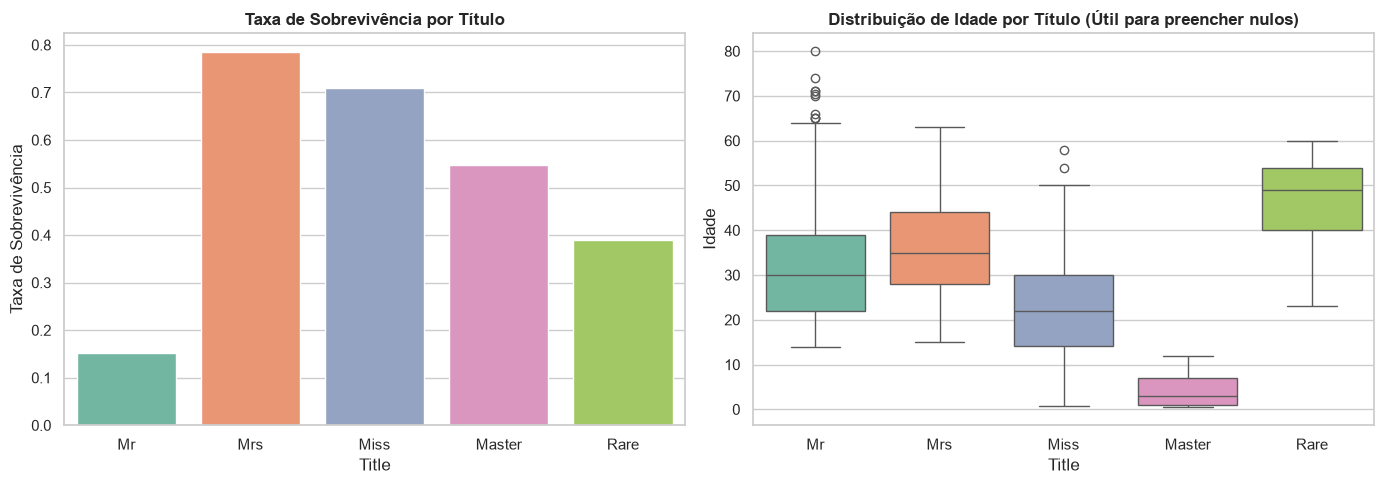

Correlação dos Títulos com Survived:


Title_Mrs       0.347373
Title_Miss      0.336459
Title_Master    0.072386
Title_Rare      0.001809
Title_Mr       -0.555587
Name: Survived, dtype: float64

In [93]:
# Extrai o pronome de tratamento (título) que vem antes do ponto no nome
df_transformed["Title"] = df["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)

print("Títulos encontrados no dataset:")
resumo_titulos = df_transformed.groupby("Title").agg(
    quantidade=("Survived", "count"),
    taxa_sobrevivencia=("Survived", "mean"),
    idade_mediana=("Age", "median"),
    idade_nulos=("Age", lambda x: x.isna().sum())
).sort_values(by="quantidade", ascending=False)
display(resumo_titulos)

# Padronizando títulos equivalentes e agrupando títulos raros
df_transformed["Title"] = df_transformed["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
titulos_principais = ["Mr", "Miss", "Mrs", "Master"]
df_transformed["Title"] = df_transformed["Title"].apply(lambda x: x if x in titulos_principais else "Rare")

print("\nResumo após agrupar títulos raros:")
display(df_transformed.groupby("Title").agg(
    quantidade=("Survived", "count"),
    taxa_sobrevivencia=("Survived", "mean"),
    idade_mediana=("Age", "median"),
    idade_nulos=("Age", lambda x: x.isna().sum())
).sort_values(by="quantidade", ascending=False))

# Gráficos de Sobrevivência e Idade por Título
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

sns.barplot(data=df_transformed, x="Title", y="Survived", hue="Title", ax=axes[0], palette="Set2", legend=False, errorbar=None)
axes[0].set_title("Taxa de Sobrevivência por Título", fontweight="bold")
axes[0].set_ylabel("Taxa de Sobrevivência")

sns.boxplot(data=df_transformed, x="Title", y="Age", hue="Title", ax=axes[1], palette="Set2", legend=False)
axes[1].set_title("Distribuição de Idade por Título (Útil para preencher nulos)", fontweight="bold")
axes[1].set_ylabel("Idade")

plt.tight_layout()
plt.show()

# Correlação de cada Título com Survived
df_titles_ohe = pd.get_dummies(df_transformed[["Survived", "Title"]], columns=["Title"], dtype=int)
corr_titles = df_titles_ohe.corr()["Survived"].drop("Survived").sort_values(ascending=False)
print("Correlação dos Títulos com Survived:")
display(corr_titles)